# Feature Engineering

In [1]:
import pandas as pd
import numpy as np
df=pd.read_csv('../data/processed/used_cars_cleaned.csv')

In [2]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_unit,mileage_value,engine_value,max_power_value,torque_value,torque_unit
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,kmpl,23.40,1248.0,74.00,190.0,nm
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,kmpl,21.14,1498.0,103.52,250.0,nm
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,kmpl,17.70,1497.0,78.00,12.7,kgm
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,kmpl,23.00,1396.0,90.00,22.4,kgm
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,kmpl,16.10,1298.0,88.20,11.5,kgm


In [3]:
print("Shape:",df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (6926, 19)

Columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'mileage_unit', 'mileage_value', 'engine_value', 'max_power_value', 'torque_value', 'torque_unit']


In [4]:
df.isnull().sum()

name                 0
year                 0
selling_price        0
km_driven            0
fuel                 0
seller_type          0
transmission         0
owner                0
mileage            208
engine             208
max_power          206
torque             209
seats              152
mileage_unit       152
mileage_value      168
engine_value       152
max_power_value    153
torque_value       156
torque_unit        163
dtype: int64

In [5]:
df.dtypes

name                   str
year                 int64
selling_price        int64
km_driven            int64
fuel                   str
seller_type            str
transmission           str
owner                  str
mileage                str
engine                 str
max_power              str
torque                 str
seats              float64
mileage_unit           str
mileage_value      float64
engine_value       float64
max_power_value    float64
torque_value       float64
torque_unit            str
dtype: object

# 1. Brand Extraction

In [6]:
# extract car brand from name column
df['brand']=df['name'].str.split().str[0]
#check the extraxted brands
df[['name','brand']].head(10)

,name,brand
0,Maruti Swift Dzire VDI,Maruti
1,Skoda Rapid 1.5 TDI Ambition,Skoda
2,Honda City 2017-2020 EXi,Honda
3,Hyundai i20 Sportz Diesel,Hyundai
4,Maruti Swift VXI BSIII,Maruti
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai
6,Maruti Wagon R LXI DUO BSIII,Maruti
7,Maruti 800 DX BSII,Maruti
8,Toyota Etios VXD,Toyota
9,Ford Figo Diesel Celebration Edition,Ford


In [7]:
#no.of unique brands 
multi_word_brands={'Land Rover':'Land Rover', 'Ashok Leyland': 'Ashok Leyland'}
df['brand'] = df['name'].apply(lambda x: next((brand for brand in multi_word_brands if x.startswith(brand)),x.split()[0]))
print("Number of Unique Brands:",df['brand'].nunique())
print("\nCount of Brands:")
print(df['brand'].value_counts())

Number of Unique Brands: 32

Count of Brands:
brand
Maruti           2165
Hyundai          1267
Mahindra          723
Tata              647
Honda             362
Ford              361
Toyota            357
Chevrolet         216
Renault           206
Volkswagen        174
Nissan             73
Skoda              70
Datsun             57
BMW                47
Mercedes-Benz      46
Fiat               44
Audi               33
Jeep               22
Mitsubishi         11
Volvo               9
Jaguar              8
Force               4
Ambassador          4
Isuzu               4
Land Rover          3
MG                  3
Daewoo              3
Kia                 3
Lexus               1
Ashok Leyland       1
Opel                1
Peugeot             1
Name: count, dtype: int64


In [8]:
#checking missing values for extracted column
df['brand'].isnull().sum()

np.int64(0)

In [9]:
#relationship between brand and selling price
df.groupby('brand')['selling_price'].median().sort_values(ascending=False)

brand
Lexus            5150000.0
Volvo            3400000.0
Jaguar           2668000.0
BMW              2150000.0
Audi             2000000.0
Land Rover       2000000.0
Mercedes-Benz    1892000.0
MG               1750000.0
Jeep             1650000.0
Isuzu            1575000.0
Kia              1575000.0
Force             880000.0
Toyota            700000.0
Mitsubishi        625000.0
Honda             560000.0
Mahindra          550000.0
Ford              450000.0
Volkswagen        422500.0
Hyundai           412000.0
Skoda             397500.0
Renault           395000.0
Nissan            370000.0
Maruti            350000.0
Datsun            300000.0
Ashok Leyland     300000.0
Fiat              282500.0
Tata              252999.0
Chevrolet         220000.0
Ambassador        110500.0
Daewoo             86000.0
Opel               68000.0
Peugeot            57000.0
Name: selling_price, dtype: float64

In [10]:
#checking how many cars are available for each brand alongside their median selling price
brand_analysis = df.groupby('brand')['selling_price'].agg(car_count='count',median_price='median').sort_values(by='median_price', ascending=False)
display(brand_analysis)

,car_count,median_price
brand,,
Lexus,1,5150000.0
Volvo,9,3400000.0
Jaguar,8,2668000.0
BMW,47,2150000.0
Audi,33,2000000.0
Land Rover,3,2000000.0
Mercedes-Benz,46,1892000.0
MG,3,1750000.0
Jeep,22,1650000.0


# 2. Car    Age Calculation

In [11]:
#checking the name column
print("Unique car names:",df['name'].nunique())

Unique car names: 2058


In [12]:
#checking car names
df['name'].head()

0          Maruti Swift Dzire VDI
1    Skoda Rapid 1.5 TDI Ambition
2        Honda City 2017-2020 EXi
3       Hyundai i20 Sportz Diesel
4          Maruti Swift VXI BSIII
Name: name, dtype: str

In [13]:
#checking if the extracted column was added
df.shape

(6926, 20)

In [14]:
#check the oldest and newest manufacturing years
print("Oldest car year:",df['year'].min())
print("Newest car year:",df['year'].max())

Oldest car year: 1983
Newest car year: 2020


In [15]:
#calculate car age using 2020 as reference year since the dataset contains car records upto 2020
df['car_age']=2020-df['year']
df[['year','car_age']].head(10)

,year,car_age
0,2014,6
1,2014,6
2,2006,14
3,2010,10
4,2007,13
5,2017,3
6,2007,13
7,2001,19
8,2011,9
9,2013,7


In [16]:
#count cars with zero age
(df['car_age']==0).sum()

np.int64(63)

In [17]:
#updated dimensions
df.shape

(6926, 21)

# 3. Average Kilometers Driven per Year

In [18]:
#check kilometers driven column
df['km_driven'].describe()

count    6.926000e+03
mean     7.399568e+04
std      5.835810e+04
min      1.000000e+00
25%      4.000000e+04
50%      7.000000e+04
75%      1.000000e+05
max      2.360457e+06
Name: km_driven, dtype: float64

In [19]:
#calculate average km driven per year, here NaN values occurs for cars with zero age
df['km_per_year']=np.where(df['car_age']>0,df['km_driven']/df['car_age'],np.nan)
df[['km_driven','car_age','km_per_year']].head(10)

,km_driven,car_age,km_per_year
0,145500,6,24250.000000
1,120000,6,20000.000000
2,140000,14,10000.000000
3,127000,10,12700.000000
4,120000,13,9230.769231
5,45000,3,15000.000000
6,175000,13,13461.538462
7,5000,19,263.157895
8,90000,9,10000.000000
9,169000,7,24142.857143


In [20]:
#statistics of km per year
df['km_per_year'].describe()

count      6863.000000
mean      13205.531771
std        9481.696741
min           0.111111
25%        7500.000000
50%       11111.111111
75%       16666.666667
max      187500.000000
Name: km_per_year, dtype: float64

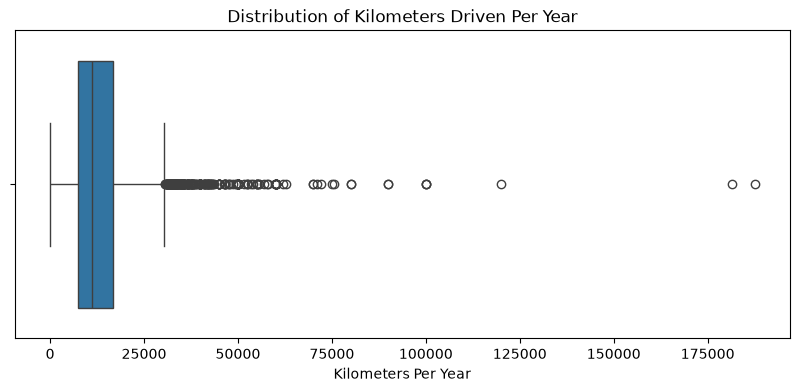

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
#visualize the distribution of km driven per year
plt.figure(figsize=(10,4))
sns.boxplot(x=df['km_per_year'])
plt.title('Distribution of Kilometers Driven Per Year')
plt.xlabel('Kilometers Per Year')
plt.show()

In [22]:
#calculating iqr upperbound for km per year
Q1 = df['km_per_year'].quantile(0.25)
Q3 = df['km_per_year'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)

Q1: 7500.0
Q3: 16666.666666666668
IQR: 9166.666666666668
Upper bound: 30416.66666666667


In [23]:
# count cars driven more than the iqr upperbound per year 
outlier_count=(df['km_per_year']>upper_bound).sum()
print("potential_outliers:",outlier_count)

potential_outliers: 278


In [24]:
#display potential outlier cars
high_usage_cars=df[df['km_per_year']>upper_bound]
print(high_usage_cars[['name','year','car_age','km_driven','km_per_year']].sort_values(by='km_per_year',ascending=False))

                                                  name  year  car_age  \
1646                            Mahindra XUV500 W6 2WD  2012        8   
3161                              Hyundai i20 Asta 1.2  2007       13   
2328                  Maruti Eeco CNG 5 Seater AC BSIV  2019        1   
5494                       Tata Zest Revotron 1.2T XMS  2019        1   
2253                 Tata Safari Storme VX Varicor 400  2019        1   
...                                                ...   ...      ...   
2836                       Hyundai Creta 1.6 SX Option  2019        1   
2616                   Fiat Linea Classic 1.3 Multijet  2014        6   
3773             Toyota Innova 2.5 G (Diesel) 7 Seater  2012        8   
6415             Toyota Innova 2.5 G (Diesel) 7 Seater  2013        7   
6108  Mahindra Bolero 2011-2019 DI NON AC BS III White  2014        6   

      km_driven    km_per_year  
1646    1500000  187500.000000  
3161    2360457  181573.615385  
2328     120000  120000.

In [25]:
#group potential outliers into average annual usage ranges
print(pd.cut(high_usage_cars['km_per_year'],bins=[upper_bound, 50000, 100000, 150000, float('inf')],include_lowest=True).value_counts().sort_index())

km_per_year
(30416.666, 50000.0]    233
(50000.0, 100000.0]      42
(100000.0, 150000.0]      1
(150000.0, inf]           2
Name: count, dtype: int64


In [26]:
#inspect cars with above 1,00,000 km
extreme_usage_cars= df[df['km_per_year'] > 100000]
print(extreme_usage_cars[['name', 'year', 'car_age', 'km_driven', 'km_per_year']].sort_values(by='km_per_year', ascending=False))

                                  name  year  car_age  km_driven  \
1646            Mahindra XUV500 W6 2WD  2012        8    1500000   
3161              Hyundai i20 Asta 1.2  2007       13    2360457   
2328  Maruti Eeco CNG 5 Seater AC BSIV  2019        1     120000   

        km_per_year  
1646  187500.000000  
3161  181573.615385  
2328  120000.000000  


In [27]:
# Inspect original and engineered values for the three cars
print(extreme_usage_cars[['name', 'year', 'km_driven', 'car_age', 'km_per_year']].to_string())

                                  name  year  km_driven  car_age    km_per_year
1646            Mahindra XUV500 W6 2WD  2012    1500000        8  187500.000000
2328  Maruti Eeco CNG 5 Seater AC BSIV  2019     120000        1  120000.000000
3161              Hyundai i20 Asta 1.2  2007    2360457       13  181573.615385


# 4. Checking Categorical Columns

In [28]:
#checking owner column
df['owner'].value_counts()

owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64

In [29]:
#checking categorical features
for col in['fuel','seller_type','transmission', 'mileage_unit', 'torque_unit']:
    print(f"\n{col}:")
    print(df[col].value_counts())


fuel:
fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

seller_type:
seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

transmission:
transmission
Manual       6342
Automatic     584
Name: count, dtype: int64

mileage_unit:
mileage_unit
kmpl     6687
km/kg      87
Name: count, dtype: int64

torque_unit:
torque_unit
nm     6283
kgm     480
Name: count, dtype: int64


# 5. Verifying New Features

In [30]:
#check missing values in the new features
print(df[['brand','car_age','km_per_year']].isnull().sum())

brand           0
car_age         0
km_per_year    63
dtype: int64


In [31]:
# Display the newly engineered features
print(df[['name', 'brand', 'year', 'car_age','km_driven', 'km_per_year']].head(10))
# Check the updated dataset shape
print("\nDataset shape:", df.shape)

                                   name    brand  year  car_age  km_driven  \
0                Maruti Swift Dzire VDI   Maruti  2014        6     145500   
1          Skoda Rapid 1.5 TDI Ambition    Skoda  2014        6     120000   
2              Honda City 2017-2020 EXi    Honda  2006       14     140000   
3             Hyundai i20 Sportz Diesel  Hyundai  2010       10     127000   
4                Maruti Swift VXI BSIII   Maruti  2007       13     120000   
5         Hyundai Xcent 1.2 VTVT E Plus  Hyundai  2017        3      45000   
6          Maruti Wagon R LXI DUO BSIII   Maruti  2007       13     175000   
7                    Maruti 800 DX BSII   Maruti  2001       19       5000   
8                      Toyota Etios VXD   Toyota  2011        9      90000   
9  Ford Figo Diesel Celebration Edition     Ford  2013        7     169000   

    km_per_year  
0  24250.000000  
1  20000.000000  
2  10000.000000  
3  12700.000000  
4   9230.769231  
5  15000.000000  
6  13461.538462

# 6. Summary

- Extracted car brands from the name column and created a new brand feature.
- Calculated car age using 2020 as reference year and created car_age.
- Calculated average kilometers per year and created km_per_year.
- Identified 278 potential outliers in km_per_year. 
- Investigated the three cars with extremely high average annual usage and retained them due to insufficient evidence of incorrect values.  
- Kept categorical features and remaining missing values unchanged for handling during the ML preprocessing stage.